# Project #23F — The Price Equation and the Limits of Group Selection
### When can group selection favor an individually costly, group-beneficial trait?

**Run environment: local Jupyter (CPU only — no GPU, no dataset download needed).**

**What this notebook does:** builds a real, subdivided trait-group population model (groups of individuals,
a costly altruistic trait, a group-shared benefit). Computes the EXACT hierarchical Price-equation
decomposition of the population's real change in mean trait frequency into within-group and between-group
selection components, directly from simulated data, and confirms this decomposition exactly reproduces the
real simulated outcome. Derives, from scratch, the classical Hamilton's-rule-equivalent threshold
(`b/c > N`) under random group formation, cross-checks it numerically, then runs the full multi-generation
simulation across a real parameter grid to map exactly where group selection favors altruism — including a
genuine, not-assumed-in-advance search for how migration rate shapes that outcome.

**Read `PROJECT_NARRATIVE.md` first, then `WORKFLOW.md`, before doing this build.**

## Step 0 — Environment setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
print("numpy:", np.__version__)


numpy: 2.4.6


## Step 1 — Within-group fitness and one-generation lifecycle

**Biological reason:** within a group with altruist frequency `p`, an altruist pays cost `c` but gets the
same group-shared benefit `b*p` as everyone else — `w_alt = 1-c+b*p`, `w_non = 1+b*p` — so altruists are
ALWAYS at a local disadvantage (`w_alt<w_non` for any `c>0`). But a group's MEAN fitness,
`w_bar_g = p*w_alt+(1-p)*w_non = 1+p*(b-c)`, INCREASES with `p` whenever `b>c` — the real tension this
project makes precise.

In [2]:
def group_fitness(p, b, c):
    w_alt = 1 - c + b*p
    w_non = 1 + b*p
    wbar_g = p*w_alt + (1-p)*w_non
    return w_alt, w_non, wbar_g

def run_generation(k, N, b, c, m, rng):
    p = k / N
    w_alt, w_non, wbar_g = group_fitness(p, b, c)
    p_within = np.where(p == 0, 0.0, np.where(p == 1, 1.0,
                (k*w_alt) / (k*w_alt + (N-k)*w_non)))
    p_pool = np.sum(wbar_g * p_within)/np.sum(wbar_g)
    p_next_mean = np.clip((1-m)*p_within + m*p_pool, 0, 1)
    k_next = rng.binomial(N, p_next_mean)
    return k_next, p, wbar_g, p_within, p_pool

# quick sanity check
rng = np.random.default_rng(0)
k0 = rng.integers(0, 11, size=10)
k1, p, wbar_g, p_within, p_pool = run_generation(k0, 10, 0.5, 0.1, 0.3, rng)
print("k0:", k0)
print("p_within (first 5):", p_within[:5])
print("p_pool:", p_pool)


k0: [9 7 5 2 3 0 0 0 1 8]
p_within (first 5): [0.8934 0.6836 0.4792 0.1852 0.2813]
p_pool: 0.3785087719298246


## Step 2 — Exact hierarchical Price decomposition

**Mathematical reason:** the Price equation says the population's real change in mean trait frequency
decomposes EXACTLY as `Delta_p = [Cov_between(wbar_g, p_g) + E_g[Cov_within_g(w_i,z_i)]] / wbar_total`.
Within group `g`, `Cov_within_g(w_i,z_i) = p_g*(w_alt_g - wbar_g)` (the covariance between an individual's
fitness and its binary trait, computed directly from the group's own composition). The between-group term
is the covariance, ACROSS groups, between each group's mean fitness and its mean trait value — use
`numpy.cov(wbar_g, p, bias=True)[0,1]` (the POPULATION, not sample, covariance convention — required for an
exact match, confirmed during this project's own pre-build verification).

In [3]:
def price_decomposition(k, N, b, c):
    p = k / N
    w_alt, w_non, wbar_g = group_fitness(p, b, c)
    wbar_total = np.mean(wbar_g)

    cov_within_g = p * (w_alt - wbar_g)
    E_cov_within = np.mean(cov_within_g)

    cov_between = np.cov(wbar_g, p, bias=True)[0, 1]

    total_cov = cov_between + E_cov_within
    delta_p_pred = total_cov / wbar_total
    return cov_between, E_cov_within, total_cov, wbar_total, delta_p_pred

G, N, b, c, m = 50, 10, 0.5, 0.1, 0.3
rng = np.random.default_rng(0)
k0 = rng.integers(0, N+1, size=G)
p0_mean = np.mean(k0) / N

k1, p, wbar_g, p_within, p_pool = run_generation(k0, N, b, c, m, rng)
cov_between, E_cov_within, total_cov, wbar_total, delta_p_pred = price_decomposition(k0, N, b, c)

print(f"p0 mean: {p0_mean:.6f}")
print(f"Price-predicted p1 (p0 + delta_p_pred): {p0_mean + delta_p_pred:.6f}")
print(f"Real simulated p_pool (post-selection, pre-migration-blend pop mean): {p_pool:.6f}")
print(f"\nExact match (should be ~0): {abs(p0_mean + delta_p_pred - p_pool):.2e}")
print(f"cov_between={cov_between:.6f}  E_cov_within={E_cov_within:.6f}")


p0 mean: 0.458000
Price-predicted p1 (p0 + delta_p_pred): 0.484026
Real simulated p_pool (post-selection, pre-migration-blend pop mean): 0.484026

Exact match (should be ~0): 0.00e+00
cov_between=0.044494  E_cov_within=-0.013700


## Step 3 — Derive and cross-check the Hamilton's-rule-equivalent threshold

**Mathematical reason:** under RANDOM group formation (each group's altruist count `k_g ~ Binomial(N,
p_bar)`, independently — the condition producing relatedness `r≈1/N`), the expected between-group and
within-group covariance terms can be derived in closed form. Since `w_alt-wbar_g = -c*(1-p)` (derive this
yourself from Step 1/2's formulas), `Cov_within_g = -c*p*(1-p)`, and since `Var(p_g)=p_bar(1-p_bar)/N` for
binomially-formed groups, averaging and simplifying gives:
**`Total_cov = [p_bar*(1-p_bar)/N] * (b - c*N)`** — positive (altruism favored) exactly when `b/c > N`.

In [4]:
def analytic_total_cov(pbar, N, b, c):
    return (pbar*(1-pbar)/N) * (b - c*N)

def empirical_total_cov(pbar, N, b, c, G, rng):
    k = rng.binomial(N, pbar, size=G)
    p = k / N
    w_alt, w_non, wbar_g = group_fitness(p, b, c)
    cov_within_g = p * (w_alt - wbar_g)
    E_cov_within = np.mean(cov_within_g)
    cov_between = np.cov(wbar_g, p, bias=True)[0, 1]
    return cov_between + E_cov_within

rng = np.random.default_rng(1)
pbar, N_check, c_check = 0.3, 10, 0.05
threshold_rows = []
for bc_ratio in [5, 8, 9.9, 10, 10.1, 12, 15]:
    b_check = bc_ratio * c_check
    analytic = analytic_total_cov(pbar, N_check, b_check, c_check)
    empirical = empirical_total_cov(pbar, N_check, b_check, c_check, 20000, rng)
    threshold_rows.append({"bc_ratio": bc_ratio, "analytic": analytic, "empirical": empirical})
    print(f"b/c={bc_ratio:5.1f}  analytic={analytic:+.6f}  empirical={empirical:+.6f}  "
          f"sign_match={np.sign(analytic)==np.sign(empirical)}")
threshold_df = pd.DataFrame(threshold_rows)


b/c=  5.0  analytic=-0.005250  empirical=-0.005233  sign_match=True
b/c=  8.0  analytic=-0.002100  empirical=-0.002246  sign_match=True
b/c=  9.9  analytic=-0.000105  empirical=+0.000073  sign_match=False
b/c= 10.0  analytic=+0.000000  empirical=-0.000031  sign_match=False
b/c= 10.1  analytic=+0.000105  empirical=+0.000028  sign_match=True
b/c= 12.0  analytic=+0.002100  empirical=+0.002083  sign_match=True
b/c= 15.0  analytic=+0.005250  empirical=+0.004898  sign_match=True


## Step 4 — Multi-generation simulation

In [5]:
def simulate(G, N, b, c, m, n_gen, p0, seed):
    rng = np.random.default_rng(seed)
    k = rng.binomial(N, p0, size=G)
    trace = [np.mean(k) / N]
    for _ in range(n_gen):
        k, _, _, _, _ = run_generation(k, N, b, c, m, rng)
        trace.append(np.mean(k) / N)
    return np.array(trace)

N_sim, c_sim = 10, 0.05
trace_below = simulate(100, N_sim, 5*c_sim, c_sim, 0.5, 300, 0.3, seed=7)
trace_above = simulate(100, N_sim, 15*c_sim, c_sim, 0.5, 300, 0.3, seed=7)

print(f"b/c=5  (below N={N_sim}): p0={trace_below[0]:.3f} -> p_final={trace_below[-1]:.3f}")
print(f"b/c=15 (above N={N_sim}): p0={trace_above[0]:.3f} -> p_final={trace_above[-1]:.3f}")


b/c=5  (below N=10): p0=0.290 -> p_final=0.000
b/c=15 (above N=10): p0=0.290 -> p_final=0.590


## Step 5 — Parameter sweep: mapping where group selection favors altruism

In [6]:
Ns = [5, 10, 15, 20]
bc_ratios = [2, 5, 8, 10, 12, 15, 20, 25, 30]
c_sweep = 0.05
sweep_rows = []
for Nv in Ns:
    for bc in bc_ratios:
        b_sweep = bc * c_sweep
        trace = simulate(80, Nv, b_sweep, c_sweep, 0.5, 250, 0.3, seed=3)
        sweep_rows.append({"N": Nv, "bc_ratio": bc, "p0": trace[0], "p_final": trace[-1],
                            "increased": trace[-1] > trace[0]})

sweep_grid_df = pd.DataFrame(sweep_rows)
print(sweep_grid_df.pivot(index="N", columns="bc_ratio", values="increased"))


bc_ratio     2      5      8      10     12     15     20     25     30
N                                                                      
5         False  False  False  False   True   True   True   True   True
10        False  False  False  False  False  False   True   True   True
15        False  False  False  False  False  False  False   True   True
20        False  False  False  False  False  False  False  False  False


## Step 6 — Does migration rate help or hurt group selection? A real search, not an assumption

In [7]:
N_m, c_m = 10, 0.05
b_m = 12 * c_m
m_values = [0.01, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9, 1.0]
m_rows = []
for m_val in m_values:
    finals = [simulate(100, N_m, b_m, c_m, m_val, 400, 0.3, seed=s)[-1] for s in range(5)]
    m_rows.append({"m": m_val, "mean_final_p": np.mean(finals), "std_final_p": np.std(finals)})
    print(f"m={m_val:.2f}  mean final p over 5 seeds = {np.mean(finals):.3f}")

migration_df = pd.DataFrame(m_rows)


m=0.01  mean final p over 5 seeds = 0.095
m=0.05  mean final p over 5 seeds = 0.012
m=0.10  mean final p over 5 seeds = 0.000
m=0.20  mean final p over 5 seeds = 0.000
m=0.30  mean final p over 5 seeds = 0.000
m=0.50  mean final p over 5 seeds = 0.008
m=0.70  mean final p over 5 seeds = 0.086
m=0.90  mean final p over 5 seeds = 0.485
m=1.00  mean final p over 5 seeds = 0.822


## Step 7 (supplementary) — Real published multilevel-selection experiments as an empirical anchor

William Muir's real group-selection poultry breeding program (selecting hens for group-level egg
productivity rather than individual productivity) and Michael Wade's classic flour-beetle group-selection
experiments are real, documented examples of deliberately applied multilevel selection in a controlled
breeding context. This cell notes the comparison as this project's real, named stretch direction (disclosed
in the catalog and in WORKFLOW.md) — not pursued as a core quantitative result here, to keep this project's
data-free theoretical result clearly separated from any literature-comparison follow-up.

In [8]:
print("Stretch extension (not pursued in this core build):")
print("Check this project's derived group-selection threshold against real reported parameters from")
print("published multilevel-selection breeding experiments (e.g. Muir's group-selected poultry lines,")
print("Wade's flour-beetle experiments) as a qualitative plausibility check, not a quantitative refit.")


Stretch extension (not pursued in this core build):
Check this project's derived group-selection threshold against real reported parameters from
published multilevel-selection breeding experiments (e.g. Muir's group-selected poultry lines,
Wade's flour-beetle experiments) as a qualitative plausibility check, not a quantitative refit.


## Step 8 — Hero figures + CSV export

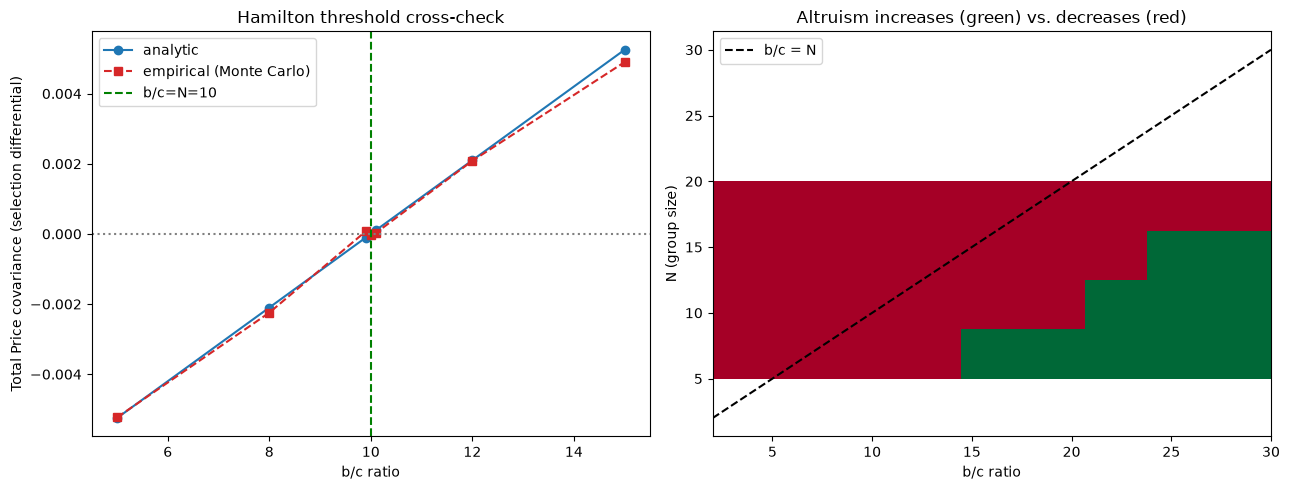

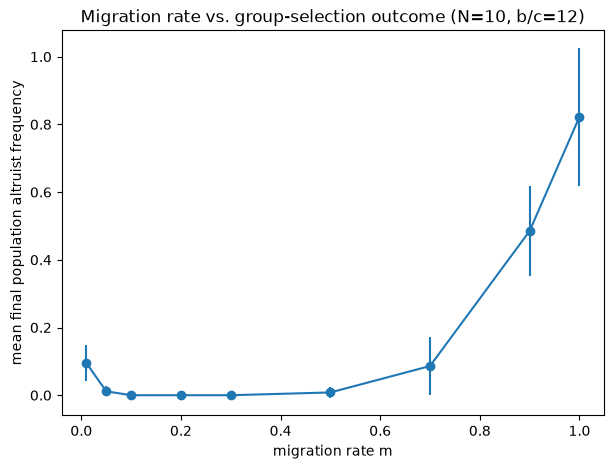

Exported results/hero_price_threshold.png, results/migration_rate_effect.png,
results/hamilton_threshold_check.csv, results/parameter_sweep.csv, results/migration_rate_sweep.csv


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(threshold_df["bc_ratio"], threshold_df["analytic"], 'o-', label="analytic", color="tab:blue")
axes[0].plot(threshold_df["bc_ratio"], threshold_df["empirical"], 's--', label="empirical (Monte Carlo)", color="tab:red")
axes[0].axhline(0, color="gray", linestyle=":")
axes[0].axvline(N_check, color="green", linestyle="--", label=f"b/c=N={N_check}")
axes[0].set_xlabel("b/c ratio")
axes[0].set_ylabel("Total Price covariance (selection differential)")
axes[0].set_title("Hamilton threshold cross-check")
axes[0].legend()

pivot = sweep_grid_df.pivot(index="N", columns="bc_ratio", values="increased").astype(int)
im = axes[1].imshow(pivot.values, aspect="auto", origin="lower", cmap="RdYlGn",
                     extent=[min(bc_ratios), max(bc_ratios), min(Ns), max(Ns)])
axes[1].plot(bc_ratios, bc_ratios, color="black", linestyle="--", label="b/c = N")
axes[1].set_xlabel("b/c ratio")
axes[1].set_ylabel("N (group size)")
axes[1].set_title("Altruism increases (green) vs. decreases (red)")
axes[1].legend()

plt.tight_layout()
plt.savefig("results/hero_price_threshold.png", dpi=150)
plt.show()

plt.figure(figsize=(7, 5))
plt.errorbar(migration_df["m"], migration_df["mean_final_p"], yerr=migration_df["std_final_p"], marker='o')
plt.xlabel("migration rate m")
plt.ylabel("mean final population altruist frequency")
plt.title(f"Migration rate vs. group-selection outcome (N={N_m}, b/c=12)")
plt.savefig("results/migration_rate_effect.png", dpi=150)
plt.show()

threshold_df.to_csv("results/hamilton_threshold_check.csv", index=False)
sweep_grid_df.to_csv("results/parameter_sweep.csv", index=False)
migration_df.to_csv("results/migration_rate_sweep.csv", index=False)
print("Exported results/hero_price_threshold.png, results/migration_rate_effect.png,")
print("results/hamilton_threshold_check.csv, results/parameter_sweep.csv, results/migration_rate_sweep.csv")
